# TabR — Behavioral Optical-Flow Features
## Train (q1–q3) · Validation (q4) · Test (q5)

Notebook ini melatih **official TabR** menggunakan `behavioral_features_events_long_unpadded.csv`. Satu baris CSV dipakai sebagai satu sampel frame-level dengan 47 fitur perilaku optical flow. Hasil akhir dilaporkan pada tiga tingkat: **frame**, **event**, dan **subject**.

### Aturan eksperimen
- **Train (q1–q3):** fitting imputer, scaler, model, dan retrieval candidates.
- **Validation (q4):** hyperparameter selection, best seed/ensemble selection, aggregation selection, dan threshold selection.
- **Test (q5):** evaluasi final setelah seluruh keputusan dikunci.
- `score`, identitas, indeks frame, dan batas onset/apex/offset **tidak menjadi fitur**.
- Split ini adalah chronological question holdout dan sekaligus fold terakhir expanding-window q-walk. Menjalankan keduanya terpisah akan menduplikasi split yang sama.

> Jalankan sel secara berurutan. Sel training dapat dilanjutkan secara idempotent melalui `continue_=True`; notebook tidak menjalankan training otomatis saat dibuka.

## 1. Setup
Memuat library proyek, mendefinisikan lokasi artefak baru, dan memakai konfigurasi tuning resmi TabR yang sudah digunakan eksperimen sebelumnya.

In [37]:
from __future__ import annotations

import copy
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from IPython.display import HTML, Markdown, display
from scipy.special import expit
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    classification_report, confusion_matrix, f1_score, log_loss, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.preprocessing import StandardScaler

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 100)
ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'opticalflow' else Path.cwd().resolve()
if not (ROOT / 'third_party' / 'tabular-dl-tabr-official').exists():
    raise RuntimeError(f'Run notebook from project root or opticalflow/: {ROOT}')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

TABR_ROOT = ROOT / 'third_party' / 'tabular-dl-tabr-official'
os.environ['PROJECT_DIR'] = str(TABR_ROOT)
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')
if str(TABR_ROOT) not in sys.path:
    sys.path.append(str(TABR_ROOT))

import lib
import bin.go

CSV_PATH = ROOT / 'opticalflow' / 'dataset' / 'behavioral_features_events_long_unpadded.csv'
BASE_TUNING_TOML = TABR_ROOT / 'exp' / 'tabr' / 'convat_apex_anxiety' / '0-tuning.toml'
DATASET_NAME = 'convat_opticalflow_behavioral_q123_q4_q5'
EXP_NAME = DATASET_NAME
DATA_DIR = TABR_ROOT / 'data' / DATASET_NAME
EXP_DIR = TABR_ROOT / 'exp' / 'tabr' / EXP_NAME
TUNING_TOML = EXP_DIR / '0-tuning.toml'
EVAL_DIR = EXP_DIR / '0-evaluation'
ENSEMBLE_DIR = EXP_DIR / '0-ensemble-5'
ARTIFACT_DIR = ROOT / 'opticalflow' / 'results' / EXP_NAME

RUN_TRAINING = False  # True hanya jika ingin tuning/training ulang
N_TUNING_TRIALS = 15
N_EVAL_SEEDS = 15
N_ENSEMBLES = 3
ENSEMBLE_SIZE = 5
SPLIT_LABELS = {'train': 'Train (q1–q3)', 'val': 'Validation (q4)', 'test': 'Test (q5)'}
LABEL_NAMES = ['anxiety_rendah', 'anxiety_tinggi']

display(pd.DataFrame({
    'Item': ['CSV', 'Dataset TabR', 'Experiment TabR', 'Run training', 'Tuning trials', 'Evaluation seeds', 'Ensembles'],
    'Value': [CSV_PATH, DATA_DIR, EXP_DIR, RUN_TRAINING, N_TUNING_TRIALS, N_EVAL_SEEDS, f'{N_ENSEMBLES} × {ENSEMBLE_SIZE} models'],
}))

,Item,Value
0,CSV,/home/ryuko/skripsi/Skripsi/Convat-1st/optical...
1,Dataset TabR,/home/ryuko/skripsi/Skripsi/Convat-1st/third_p...
2,Experiment TabR,/home/ryuko/skripsi/Skripsi/Convat-1st/third_p...
3,Run training,False
4,Tuning trials,15
5,Evaluation seeds,15
6,Ensembles,3 × 5 models


## 2. Load dan validasi fitur
Daftar fitur dibuat secara eksplisit dari sembilan keluarga fitur perilaku. Validasi di bawah menghentikan proses bila metadata, `score`, atau identifier tanpa sengaja masuk ke model.

In [38]:
if not CSV_PATH.exists():
    raise FileNotFoundError(CSV_PATH)
if not BASE_TUNING_TOML.exists():
    raise FileNotFoundError(BASE_TUNING_TOML)

df = pd.read_csv(CSV_PATH)
FEATURE_PREFIXES = (
    'mean_dx_', 'mean_dy_', 'raw_mag_', 'energy_', 'dir_consist_',
    'accel_', 'jerk_', 'sync_', 'sym_',
)
FEATURE_COLS = [c for c in df.columns if c.startswith(FEATURE_PREFIXES)]
META_COLS = [c for c in df.columns if c not in FEATURE_COLS]
FORBIDDEN_FEATURES = {
    'event_id', 'subject_id', 'clip', 'event_idx', 'onset_frame', 'apex_frame',
    'offset_frame', 'frame_in_event', 'absolute_frame', 'label', 'score',
}

assert len(FEATURE_COLS) == 47, f'Expected 47 behavioral features, got {len(FEATURE_COLS)}'
assert FORBIDDEN_FEATURES.isdisjoint(FEATURE_COLS)
assert FORBIDDEN_FEATURES.issubset(df.columns)
assert set(df['clip'].unique()) == {'q1', 'q2', 'q3', 'q4', 'q5'}
assert set(df['label'].unique()) == {0, 1}
assert not df[FEATURE_COLS].isna().any().any()
assert all(pd.api.types.is_numeric_dtype(df[c]) for c in FEATURE_COLS)
assert df.groupby('event_id')['label'].nunique().max() == 1
assert not df.duplicated(['event_id', 'frame_in_event']).any()

df['target'] = df['label'].astype(np.int64)
df['question_no'] = df['clip'].str.removeprefix('q').astype(int)
df['event_length'] = df['offset_frame'] - df['onset_frame']

feature_audit = pd.DataFrame({
    'Check': ['Total rows', 'Total events', 'Total subjects', 'Behavioral features', 'Missing feature values', 'Duplicate event/frame', 'Forbidden columns used'],
    'Result': [len(df), df['event_id'].nunique(), df['subject_id'].nunique(), len(FEATURE_COLS), int(df[FEATURE_COLS].isna().sum().sum()), int(df.duplicated(['event_id', 'frame_in_event']).sum()), sorted(FORBIDDEN_FEATURES.intersection(FEATURE_COLS))],
    'Status': ['PASS'] * 7,
})
display(feature_audit.style.hide(axis='index').map(lambda _: 'color: #137333; font-weight: 600', subset=['Status']))
display(pd.DataFrame({'Feature': FEATURE_COLS, 'dtype': [str(df[c].dtype) for c in FEATURE_COLS]}).T)

Check,Result,Status
Total rows,15537,PASS
Total events,644,PASS
Total subjects,90,PASS
Behavioral features,47,PASS
Missing feature values,0,PASS
Duplicate event/frame,0,PASS
Forbidden columns used,[],PASS


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46
Feature,mean_dx_left_eye,mean_dx_right_eye,mean_dx_lips,mean_dx_left_eyebrow,mean_dx_right_eyebrow,mean_dy_left_eye,mean_dy_right_eye,mean_dy_lips,mean_dy_left_eyebrow,mean_dy_right_eyebrow,raw_mag_left_eye,raw_mag_right_eye,raw_mag_lips,raw_mag_left_eyebrow,raw_mag_right_eyebrow,energy_left_eye,energy_right_eye,energy_lips,energy_left_eyebrow,energy_right_eyebrow,dir_consist_left_eye,dir_consist_right_eye,dir_consist_lips,dir_consist_left_eyebrow,dir_consist_right_eyebrow,accel_left_eye,accel_right_eye,accel_lips,accel_left_eyebrow,accel_right_eyebrow,jerk_left_eye,jerk_right_eye,jerk_lips,jerk_left_eyebrow,jerk_right_eyebrow,sync_left_eye_right_eye,sync_left_eye_lips,sync_left_eye_left_eyebrow,sync_left_eye_right_eyebrow,sync_right_eye_lips,sync_right_eye_left_eyebrow,sync_right_eye_right_eyebrow,sync_lips_left_eyebrow,sync_lips_right_eyebrow,sync_left_eyebrow_right_eyebrow,sym_left_eye_right_eye,sym_left_eyebrow_right_eyebrow
dtype,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64


## 3. Split audit dan exploratory visualization
Seluruh row dari event yang sama tetap berada dalam satu question split. Grafik menunjukkan jumlah frame, event, distribusi label, panjang event, dan overlap subject. Overlap subject berarti eksperimen ini mengukur generalisasi ke pertanyaan berikutnya, bukan subject-independent generalization.

Split,Frames,Events,Subjects,Label 0 events,Label 1 events,Positive event rate,Median event length
Train (q1–q3),10195,422,88,150,272,64.5%,24.0
Validation (q4),2960,123,59,41,82,66.7%,24.0
Test (q5),2382,99,49,26,73,73.7%,24.0


Pair,Shared subjects
Train (q1–q3) ∩ Validation (q4),57
Train (q1–q3) ∩ Test (q5),47
Validation (q4) ∩ Test (q5),41


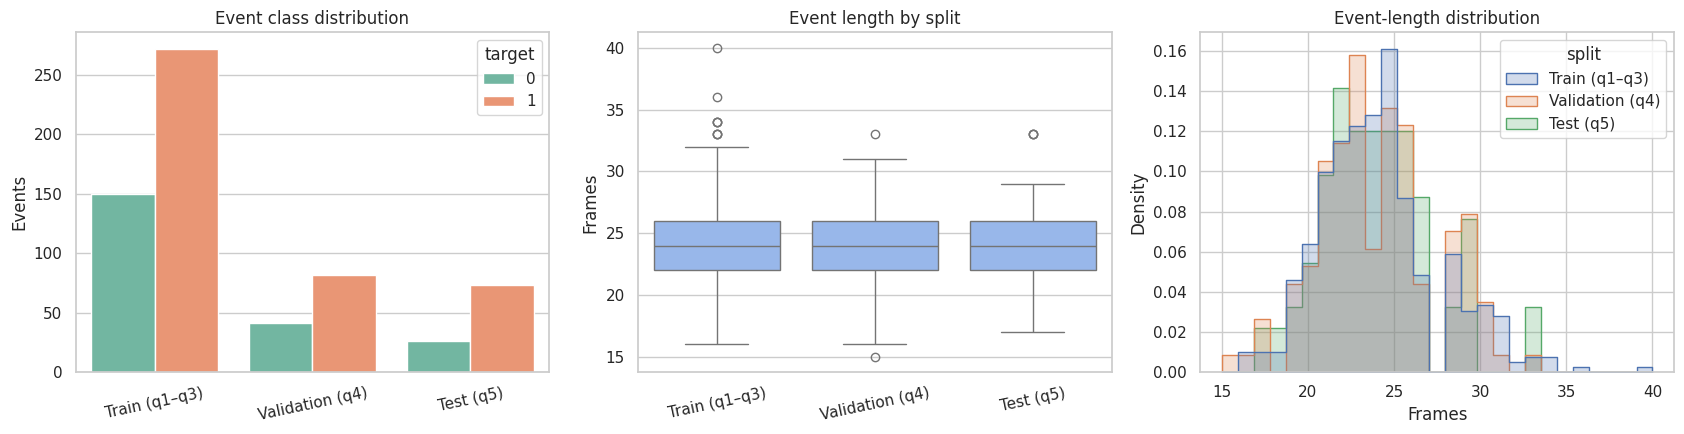

In [39]:
QUESTION_SPLITS = {'train': {1, 2, 3}, 'val': {4}, 'test': {5}}
split_frames = {part: df[df['question_no'].isin(qs)].copy() for part, qs in QUESTION_SPLITS.items()}
assert sum(len(x) for x in split_frames.values()) == len(df)
event_sets = {part: set(x['event_id']) for part, x in split_frames.items()}
assert not (event_sets['train'] & event_sets['val'] or event_sets['train'] & event_sets['test'] or event_sets['val'] & event_sets['test'])

summary_rows = []
for part, part_df in split_frames.items():
    events = part_df.drop_duplicates('event_id')
    counts = events['target'].value_counts()
    summary_rows.append({
        'Split': SPLIT_LABELS[part], 'Frames': len(part_df), 'Events': len(events),
        'Subjects': part_df['subject_id'].nunique(), 'Label 0 events': int(counts.get(0, 0)),
        'Label 1 events': int(counts.get(1, 0)), 'Positive event rate': counts.get(1, 0) / len(events),
        'Median event length': events['event_length'].median(),
    })
split_summary = pd.DataFrame(summary_rows)
display(split_summary.style.hide(axis='index').format({'Positive event rate': '{:.1%}', 'Median event length': '{:.1f}'}))

subject_sets = {part: set(x['subject_id']) for part, x in split_frames.items()}
overlap = pd.DataFrame([
    {'Pair': 'Train (q1–q3) ∩ Validation (q4)', 'Shared subjects': len(subject_sets['train'] & subject_sets['val'])},
    {'Pair': 'Train (q1–q3) ∩ Test (q5)', 'Shared subjects': len(subject_sets['train'] & subject_sets['test'])},
    {'Pair': 'Validation (q4) ∩ Test (q5)', 'Shared subjects': len(subject_sets['val'] & subject_sets['test'])},
])
display(overlap.style.hide(axis='index'))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
plot_df = pd.concat([x.assign(split=SPLIT_LABELS[p]) for p, x in split_frames.items()])
sns.countplot(data=plot_df.drop_duplicates('event_id'), x='split', hue='target', ax=axes[0], palette='Set2')
axes[0].set(title='Event class distribution', xlabel='', ylabel='Events')
axes[0].tick_params(axis='x', rotation=12)
sns.boxplot(data=plot_df.drop_duplicates('event_id'), x='split', y='event_length', ax=axes[1], color='#8ab4f8')
axes[1].set(title='Event length by split', xlabel='', ylabel='Frames')
axes[1].tick_params(axis='x', rotation=12)
sns.histplot(data=plot_df.drop_duplicates('event_id'), x='event_length', hue='split', element='step', stat='density', common_norm=False, ax=axes[2])
axes[2].set(title='Event-length distribution', xlabel='Frames')
plt.tight_layout()
plt.show()

## 4. Export official TabR dataset
Imputer dan scaler di-fit hanya pada Train (q1–q3), lalu diterapkan ke Validation (q4) dan Test (q5). File split CSV dipertahankan untuk menghubungkan prediksi TabR kembali ke event dan subject. Sel ini aman dijalankan ulang dan hanya menulis artefak eksperimen bernama baru.

In [40]:
def export_official_dataset() -> pd.DataFrame:
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    imputer = SimpleImputer(strategy='mean')
    scaler = StandardScaler()
    transformed = {}
    transformed['train'] = scaler.fit_transform(imputer.fit_transform(split_frames['train'][FEATURE_COLS])).astype(np.float32)
    for part in ('val', 'test'):
        transformed[part] = scaler.transform(imputer.transform(split_frames[part][FEATURE_COLS])).astype(np.float32)
    for part, part_df in split_frames.items():
        np.save(DATA_DIR / f'X_num_{part}.npy', transformed[part])
        np.save(DATA_DIR / f'Y_{part}.npy', part_df['target'].to_numpy(np.int64))
        part_df.to_csv(DATA_DIR / f'{part}_split.csv', index=False)
    (DATA_DIR / 'READY').write_text('')
    (DATA_DIR / 'info.json').write_text(json.dumps({'task_type': 'binclass', 'name': DATASET_NAME, 'id': DATASET_NAME}, indent=2))
    (DATA_DIR / 'feature_cols.json').write_text(json.dumps(FEATURE_COLS, indent=2))
    (DATA_DIR / 'preprocessing.json').write_text(json.dumps({
        'imputer': 'mean fitted on Train (q1-q3)', 'scaler': 'StandardScaler fitted on Train (q1-q3)',
        'feature_count': len(FEATURE_COLS), 'excluded_columns': META_COLS,
    }, indent=2))
    return pd.DataFrame([
        {'Split': SPLIT_LABELS[p], 'X shape': str(transformed[p].shape), 'X dtype': str(transformed[p].dtype), 'Y shape': str((len(split_frames[p]),)), 'Y dtype': 'int64'}
        for p in ('train', 'val', 'test')
    ])

export_table = export_official_dataset()
display(Markdown(f'**Official dataset ready:** `{DATA_DIR}`'))
display(export_table.style.hide(axis='index'))

**Official dataset ready:** `/home/ryuko/skripsi/Skripsi/Convat-1st/third_party/tabular-dl-tabr-official/data/convat_opticalflow_behavioral_q123_q4_q5`

Split,X shape,X dtype,Y shape,Y dtype
Train (q1–q3),"(10195, 47)",float32,"(10195,)",int64
Validation (q4),"(2960, 47)",float32,"(2960,)",int64
Test (q5),"(2382, 47)",float32,"(2382,)",int64


## 5. Siapkan tuning resmi TabR — 15 trials
Search space mengikuti konfigurasi resmi yang sudah dipakai repo: `context_size`, lebar model, dropout, jumlah block, learning rate, dan weight decay. `batch_size=128`, cache dataset, serta early stopping menjaga training stabil tanpa sengaja mengecilkan model.

In [41]:
def prepare_tuning_config() -> dict:
    config = copy.deepcopy(lib.load_config(BASE_TUNING_TOML))
    config['n_trials'] = N_TUNING_TRIALS
    config['space']['data']['path'] = f':data/{DATASET_NAME}'
    EXP_DIR.mkdir(parents=True, exist_ok=True)
    lib.dump_config(config, TUNING_TOML)
    return config

tuning_config = prepare_tuning_config()
display(Markdown(f'**Tuning config ready:** `{TUNING_TOML}`'))
display(pd.DataFrame([
    {'Setting': 'Trials', 'Value': tuning_config['n_trials']},
    {'Setting': 'Batch size', 'Value': tuning_config['space']['batch_size']},
    {'Setting': 'Patience', 'Value': tuning_config['space']['patience']},
    {'Setting': 'Context size search', 'Value': str(tuning_config['space']['context_size'])},
    {'Setting': 'Model width search', 'Value': str(tuning_config['space']['model']['d_main'])},
    {'Setting': 'Dataset', 'Value': tuning_config['space']['data']['path']},
]).style.hide(axis='index'))

**Tuning config ready:** `/home/ryuko/skripsi/Skripsi/Convat-1st/third_party/tabular-dl-tabr-official/exp/tabr/convat_opticalflow_behavioral_q123_q4_q5/0-tuning.toml`

Setting,Value
Trials,15
Batch size,128
Patience,6
Context size search,"['_tune_', 'int', 4, 16]"
Model width search,"['_tune_', 'int', 96, 256]"
Dataset,:data/convat_opticalflow_behavioral_q123_q4_q5


## 6. Jalankan tuning, 15 evaluation seeds, dan 3 ensemble
Sel berikut adalah satu-satunya sel training. Official `bin.go.main` menjalankan **15 tuning trials**, mengevaluasi konfigurasi terbaik pada **15 seed**, lalu membentuk **3 ensemble berisi 5 model**. Output lama tidak ditimpa; proses yang belum selesai dapat dilanjutkan.

> Waktu tuning sebelumnya pada laptop RTX 3050 untuk search space serupa sekitar dua jam; dataset dan epoch aktual menentukan waktu akhir.

In [42]:
# TRAINING CELL — default skip agar Run All hanya membaca artefak yang sudah ada.
if RUN_TRAINING:
    bin.go.main(
        TUNING_TOML,
        n_seeds=N_EVAL_SEEDS,
        n_ensembles=N_ENSEMBLES,
        ensemble_size=ENSEMBLE_SIZE,
        continue_=True,
        force=False,
    )
else:
    display(Markdown('> Training dilewati (`RUN_TRAINING = False`); memakai artefak eksperimen yang sudah tersedia.'))

> Training dilewati (`RUN_TRAINING = False`); memakai artefak eksperimen yang sudah tersedia.

## 7. Tuning summary dan trial ranking
Sel analisis berikut dapat dijalankan setelah training selesai. Ranking trial hanya menggunakan **Validation (q4)** dari checkpoint Optuna. Test (q5) tetap tertutup sampai konfigurasi dan model terkunci.

,Trial,Validation (q4) accuracy,Best epoch,Parameters,Context,d_main,Encoder blocks,Predictor blocks,Learning rate,Weight decay
0,10,0.7054,17,1207613,4,238,2,2,4.61e-05,7.94e-06
1,12,0.7054,10,1384906,4,255,2,2,7.89e-05,1.06e-05
2,13,0.7027,7,1147937,4,232,2,2,1.09e-04,2.67e-05
3,11,0.7017,24,1395713,5,256,2,2,4.50e-05,8.56e-06
4,3,0.7000,32,485971,4,167,2,1,2.52e-05,2.24e-06
5,1,0.6983,4,364816,10,165,1,1,1.29e-04,1.29e-04
6,14,0.6976,9,1061258,9,223,2,2,2.03e-04,6.09e-06
7,8,0.6970,2,294521,7,148,1,1,3.87e-04,1.19e-05
8,7,0.6959,4,533201,7,200,1,1,2.12e-04,8.10e-05
9,6,0.6946,2,758348,14,239,1,1,6.24e-05,2.58e-04


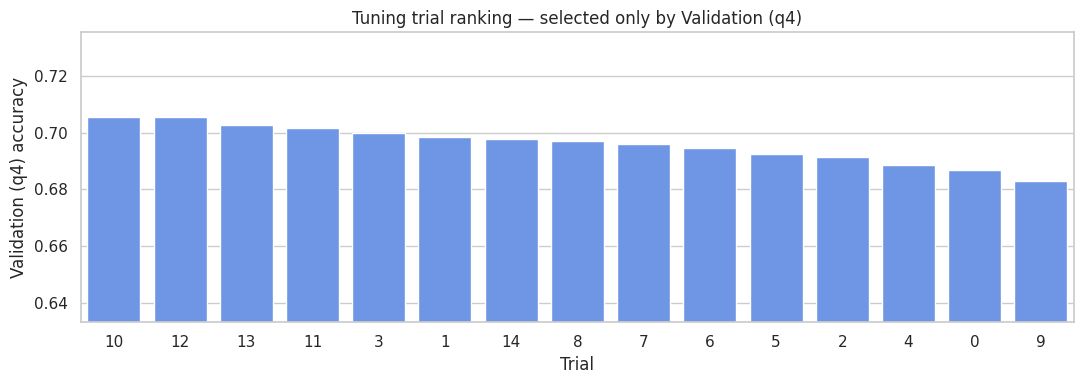

In [43]:
def require_artifact(path: Path, message: str) -> None:
    if not path.exists():
        raise FileNotFoundError(f'{message}: {path}')

require_artifact(EXP_DIR / '0-tuning' / 'checkpoint.pt', 'Run the training cell first')
tuning_checkpoint = lib.load_checkpoint(EXP_DIR / '0-tuning', map_location='cpu')
trial_rows = []
for report in tuning_checkpoint['trial_reports']:
    cfg = report['config']
    trial_rows.append({
        'Trial': report['trial_id'], 'Validation (q4) accuracy': report['metrics']['val']['score'],
        'Best epoch': report['best_epoch'], 'Parameters': report['n_parameters'],
        'Context': cfg['context_size'], 'd_main': cfg['model']['d_main'],
        'Encoder blocks': cfg['model']['encoder_n_blocks'], 'Predictor blocks': cfg['model']['predictor_n_blocks'],
        'Learning rate': cfg['optimizer']['lr'], 'Weight decay': cfg['optimizer']['weight_decay'],
    })
trial_df = pd.DataFrame(trial_rows).sort_values('Validation (q4) accuracy', ascending=False).reset_index(drop=True)
display(trial_df.style.format({'Validation (q4) accuracy': '{:.4f}', 'Learning rate': '{:.2e}', 'Weight decay': '{:.2e}'}).background_gradient(subset=['Validation (q4) accuracy'], cmap='Blues'))

plt.figure(figsize=(11, 4))
sns.barplot(data=trial_df, x='Trial', y='Validation (q4) accuracy', color='#5b8ff9', order=trial_df['Trial'])
plt.title('Tuning trial ranking — selected only by Validation (q4)')
plt.ylim(max(0, trial_df['Validation (q4) accuracy'].min() - 0.05), min(1, trial_df['Validation (q4) accuracy'].max() + 0.03))
plt.tight_layout()
plt.show()

## 8. Load predictions dan metric helpers
Prediksi single model tersimpan sebagai logits, sedangkan ensemble tersimpan sebagai probabilitas. Helper di bawah menormalisasi keduanya dan menyediakan evaluasi konsisten untuk semua split dan level.

In [53]:
def load_probabilities(run_dir: Path) -> dict[str, np.ndarray]:
    report = json.loads((run_dir / 'report.json').read_text())
    predictions = lib.load_predictions(run_dir)
    if report.get('prediction_type') == 'logits':
        return {part: expit(np.asarray(values)) for part, values in predictions.items()}
    return {part: np.asarray(values) for part, values in predictions.items()}

def metric_row(y_true: np.ndarray, prob: np.ndarray, threshold: float, level: str, part: str, source: str) -> dict:
    y_true = np.asarray(y_true, dtype=int)
    prob = np.asarray(prob, dtype=float)
    pred = (prob >= threshold).astype(int)
    both = len(np.unique(y_true)) == 2
    return {
        'Source': source, 'Level': level, 'Split': SPLIT_LABELS[part], 'N': len(y_true), 'Threshold': threshold,
        'Accuracy': accuracy_score(y_true, pred), 'Balanced accuracy': balanced_accuracy_score(y_true, pred),
        'Macro-F1': f1_score(y_true, pred, average='macro', zero_division=0),
        'Weighted-F1': f1_score(y_true, pred, average='weighted', zero_division=0),
        'Precision class 1': precision_score(y_true, pred, zero_division=0),
        'Recall class 1': recall_score(y_true, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, prob) if both else np.nan,
        'PR-AUC': average_precision_score(y_true, prob) if both else np.nan,
    }

def aggregate_events(part_df: pd.DataFrame, prob: np.ndarray, method: str) -> pd.DataFrame:
    work = part_df[['event_id', 'subject_id', 'target', 'event_length', 'onset_frame', 'apex_frame', 'offset_frame']].copy()
    work['probability'] = prob
    def aggregate(values: pd.Series) -> float:
        arr = values.to_numpy(float)
        if method == 'mean': return float(arr.mean())
        if method == 'median': return float(np.median(arr))
        if method == 'max': return float(arr.max())
        if method == 'top3_mean': return float(np.sort(arr)[-min(3, len(arr)):].mean())
        raise ValueError(method)
    metadata = work.groupby('event_id', sort=False).agg({
        'subject_id': 'first', 'target': 'first', 'event_length': 'first',
        'onset_frame': 'first', 'apex_frame': 'first', 'offset_frame': 'first',
    })
    metadata['probability'] = work.groupby('event_id', sort=False)['probability'].apply(aggregate)
    return metadata.reset_index()

def aggregate_subjects(event_df: pd.DataFrame) -> pd.DataFrame:
    consistency = event_df.groupby('subject_id')['target'].nunique()
    if consistency.max() != 1:
        raise ValueError('A subject has inconsistent labels within a split')
    return event_df.groupby('subject_id', as_index=False).agg(target=('target', 'first'), probability=('probability', 'mean'), events=('event_id', 'size'))

def classification_report_table(y_true: np.ndarray, prob: np.ndarray, threshold: float) -> pd.DataFrame:
    y_true = np.asarray(y_true, dtype=int)
    prob = np.asarray(prob, dtype=float)
    pred = (prob >= threshold).astype(int)
    report = classification_report(y_true, pred, labels=[0, 1], output_dict=True, zero_division=0)
    rows = [{'': LABEL_NAMES[i], **report[str(i)]} for i in (0, 1)]
    rows.extend([
        {'': 'accuracy', 'precision': report['accuracy'], 'recall': report['accuracy'], 'f1-score': report['accuracy'], 'support': len(y_true)},
        {'': 'macro avg', **report['macro avg']},
        {'': 'weighted avg', **report['weighted avg']},
        {'': 'cross-entropy', 'precision': log_loss(y_true, prob, labels=[0, 1]), 'recall': np.nan, 'f1-score': np.nan, 'support': np.nan},
        {'': 'roc-auc', 'precision': roc_auc_score(y_true, prob), 'recall': np.nan, 'f1-score': np.nan, 'support': np.nan},
        {'': 'score', 'precision': report['accuracy'], 'recall': np.nan, 'f1-score': np.nan, 'support': np.nan},
    ])
    return pd.DataFrame(rows).set_index('')

def display_reports_one_row(level: str, level_data: dict) -> None:
    threshold = 0.5 if level == 'Frame' else SELECTED_THRESHOLD
    panels = []
    for part in ('train', 'val', 'test'):
        data = level_data[(part, level)]
        y = data['target'].to_numpy(int)
        prob = data['probability'].to_numpy(float)
        pred = (prob >= threshold).astype(int)
        report = classification_report(y, pred, labels=[0, 1], output_dict=True, zero_division=0)
        rows = [
            ('0', report['0']['precision'], report['0']['recall'], report['0']['f1-score'], int(report['0']['support'])),
            ('1', report['1']['precision'], report['1']['recall'], report['1']['f1-score'], int(report['1']['support'])),
            ('accuracy', report['accuracy'], report['accuracy'], report['accuracy'], len(y)),
            ('macro avg', report['macro avg']['precision'], report['macro avg']['recall'], report['macro avg']['f1-score'], len(y)),
            ('weighted avg', report['weighted avg']['precision'], report['weighted avg']['recall'], report['weighted avg']['f1-score'], len(y)),
            ('cross-entropy', log_loss(y, prob, labels=[0, 1]), None, None, None),
            ('roc-auc', roc_auc_score(y, prob), None, None, None),
            ('score', report['accuracy'], None, None, None),
        ]
        fmt = lambda value: '—' if value is None else f'{value:.4f}'
        body = ''.join(
            f"<tr><th>{name}</th><td>{fmt(precision)}</td><td>{fmt(recall)}</td>"
            f"<td>{fmt(f1)}</td><td>{'—' if support is None else f'{support:,}'}</td></tr>"
            for name, precision, recall, f1, support in rows
        )
        panels.append(f"""<div class='cr-panel'><div class='cr-title'>{SPLIT_LABELS[part]}</div>
        <table><thead><tr><th></th><th>precision</th><th>recall</th><th>f1-score</th><th>support</th></tr></thead>
        <tbody>{body}</tbody></table></div>""")
    css = """<style>
      .cr-row{display:flex;gap:18px;width:100%;overflow-x:auto;padding:2px 0 8px;font-family:Arial,sans-serif;color:#3f4775}
      .cr-panel{flex:1 0 390px;max-width:430px}
      .cr-title{text-align:center;font-size:13px;font-weight:700;padding:7px 0;color:#454d78}
      .cr-panel table{width:100%;border-collapse:collapse;font-size:12px;font-variant-numeric:tabular-nums}
      .cr-panel th,.cr-panel td{padding:6px 8px;text-align:right;white-space:nowrap}
      .cr-panel thead th{background:#e7e3e3;font-weight:700}
      .cr-panel tbody th{font-weight:400;text-align:right;width:105px}
      .cr-panel tbody tr:nth-child(odd){background:#f3efef}
      .cr-panel tbody tr:nth-child(even){background:#ebe7e7}
    </style>"""
    display(HTML(css + "<div class='cr-row'>" + ''.join(panels) + '</div>'))

def select_event_rule(part_df: pd.DataFrame, prob: np.ndarray) -> tuple[pd.DataFrame, dict]:
    rows = []
    thresholds = np.round(np.arange(0.05, 0.951, 0.01), 2)
    for method in ('mean', 'median', 'max', 'top3_mean'):
        event_df = aggregate_events(part_df, prob, method)
        for threshold in thresholds:
            row = metric_row(event_df['target'].to_numpy(), event_df['probability'].to_numpy(), threshold, 'Event', 'val', method)
            rows.append(row)
    search = pd.DataFrame(rows)
    search['Distance to 0.5'] = (search['Threshold'] - 0.5).abs()
    best = search.sort_values(['Macro-F1', 'Balanced accuracy', 'Distance to 0.5'], ascending=[False, False, True]).iloc[0].to_dict()
    return search, best

## 9. Seed stability dan best-seed selection
Setiap seed dievaluasi dengan rule event yang dipilih hanya pada Validation (q4). Best seed juga dipilih dari Validation (q4). Tabel dan boxplot menunjukkan stabilitas, termasuk mean ± standard deviation wajib.

### Best seed selected by Validation (q4): **2**

Split,macro_f1_mean,macro_f1_std,balanced_accuracy_mean,balanced_accuracy_std,accuracy_mean,accuracy_std
Test (q5),0.7236,0.0339,0.7319,0.0349,0.7811,0.0416
Train (q1–q3),0.7751,0.0307,0.7769,0.0288,0.7938,0.0314
Validation (q4),0.7384,0.0198,0.7407,0.0244,0.7686,0.0226


,Seed,Split,Aggregation,Threshold,Accuracy,Balanced accuracy,Macro-F1,ROC-AUC,PR-AUC
0,0,Train (q1–q3),mean,0.6600,0.8412,0.8215,0.8249,0.8854,0.9292
1,0,Validation (q4),mean,0.6600,0.7967,0.7622,0.7669,0.8123,0.8594
2,0,Test (q5),mean,0.6600,0.7879,0.7200,0.7227,0.8404,0.9277
3,1,Train (q1–q3),mean,0.6700,0.7962,0.7672,0.7726,0.8663,0.9143
4,1,Validation (q4),mean,0.6700,0.7724,0.7256,0.7334,0.7844,0.8724
5,1,Test (q5),mean,0.6700,0.7778,0.6760,0.6885,0.8646,0.9402
6,2,Train (q1–q3),max,0.8500,0.8175,0.8136,0.8055,0.8700,0.9178
7,2,Validation (q4),max,0.8500,0.8130,0.7805,0.7856,0.8314,0.8994
8,2,Test (q5),max,0.8500,0.7677,0.7187,0.7105,0.8398,0.9350
9,3,Train (q1–q3),top3_mean,0.7900,0.7725,0.7697,0.7595,0.8517,0.9016


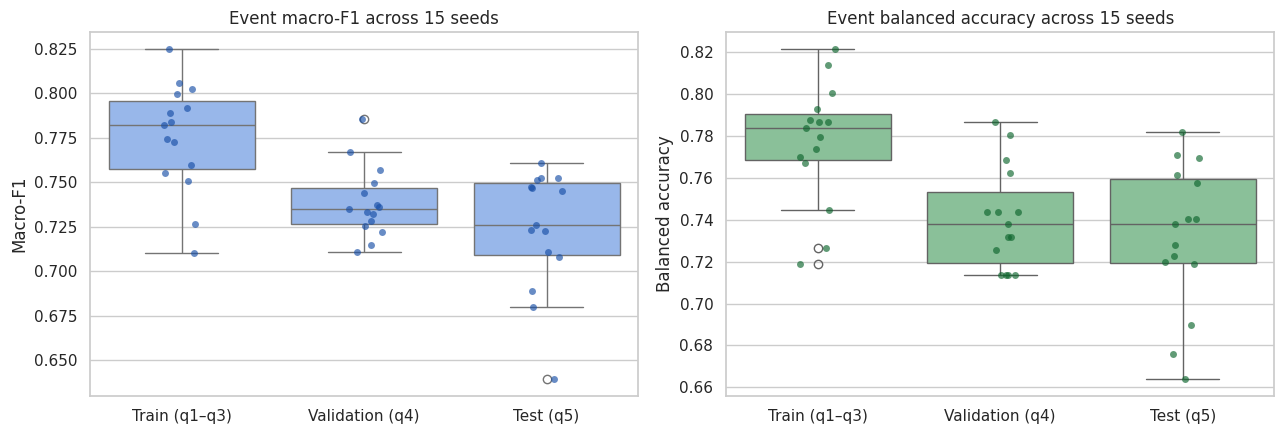

In [45]:
require_artifact(EVAL_DIR, 'Evaluation outputs are missing')
seed_rows = []
seed_rules = {}
for seed in range(N_EVAL_SEEDS):
    run_dir = EVAL_DIR / str(seed)
    require_artifact(run_dir / 'DONE', f'Seed {seed} is incomplete')
    probs = load_probabilities(run_dir)
    _, rule = select_event_rule(split_frames['val'], probs['val'])
    seed_rules[seed] = rule
    for part in ('train', 'val', 'test'):
        events = aggregate_events(split_frames[part], probs[part], rule['Source'])
        row = metric_row(events['target'].to_numpy(), events['probability'].to_numpy(), rule['Threshold'], 'Event', part, f'Seed {seed}')
        row['Seed'] = seed
        row['Aggregation'] = rule['Source']
        seed_rows.append(row)
seed_metrics = pd.DataFrame(seed_rows)
best_seed = int(seed_metrics[seed_metrics['Split'] == SPLIT_LABELS['val']].sort_values(['Macro-F1', 'Balanced accuracy'], ascending=False).iloc[0]['Seed'])
stability = seed_metrics.groupby('Split').agg(
    macro_f1_mean=('Macro-F1', 'mean'), macro_f1_std=('Macro-F1', 'std'),
    balanced_accuracy_mean=('Balanced accuracy', 'mean'), balanced_accuracy_std=('Balanced accuracy', 'std'),
    accuracy_mean=('Accuracy', 'mean'), accuracy_std=('Accuracy', 'std'),
).reset_index()
display(Markdown(f'### Best seed selected by Validation (q4): **{best_seed}**'))
display(stability.style.hide(axis='index').format({c: '{:.4f}' for c in stability.columns if c != 'Split'}))
display(seed_metrics[['Seed', 'Split', 'Aggregation', 'Threshold', 'Accuracy', 'Balanced accuracy', 'Macro-F1', 'ROC-AUC', 'PR-AUC']].style.format({c: '{:.4f}' for c in ['Threshold', 'Accuracy', 'Balanced accuracy', 'Macro-F1', 'ROC-AUC', 'PR-AUC']}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=seed_metrics, x='Split', y='Macro-F1', ax=axes[0], color='#8ab4f8')
sns.stripplot(data=seed_metrics, x='Split', y='Macro-F1', ax=axes[0], color='#174ea6', alpha=.65)
axes[0].set(title='Event macro-F1 across 15 seeds', xlabel='')
sns.boxplot(data=seed_metrics, x='Split', y='Balanced accuracy', ax=axes[1], color='#81c995')
sns.stripplot(data=seed_metrics, x='Split', y='Balanced accuracy', ax=axes[1], color='#0d652d', alpha=.65)
axes[1].set(title='Event balanced accuracy across 15 seeds', xlabel='')
plt.tight_layout()
plt.show()

## 10. Training curves — Train vs Validation
Official checkpoint mencatat train loss setiap epoch serta validation loss/accuracy. Best epoch ditentukan oleh validation performance. Test curve sengaja tidak dipakai untuk memilih epoch.

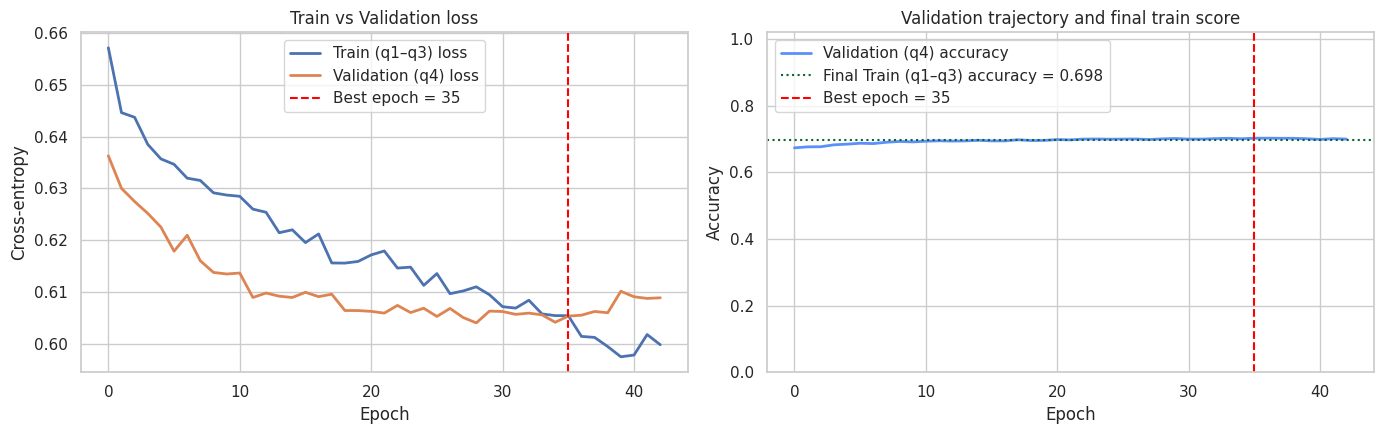

Best seed,Best epoch,Parameters,Training time
2,35,1207613,0:01:11.575610


In [46]:
best_run_dir = EVAL_DIR / str(best_seed)
checkpoint = lib.load_checkpoint(best_run_dir, map_location='cpu')
best_report = json.loads((best_run_dir / 'report.json').read_text())
curve_rows = []
for epoch, item in enumerate(checkpoint['training_log']):
    metrics = item['metrics']
    epoch_losses = item.get('epoch-losses', [])
    curve_rows.append({
        'Epoch': epoch,
        'Train loss': float(np.mean(epoch_losses)) if len(epoch_losses) else np.nan,
        'Validation loss': float(metrics['val'].get('cross-entropy', np.nan)),
        'Validation accuracy': float(metrics['val']['score']),
    })
curve_df = pd.DataFrame(curve_rows)
best_epoch = int(best_report['best_epoch'])
final_train_accuracy = float(best_report['metrics']['train']['score'])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(curve_df['Epoch'], curve_df['Train loss'], label='Train (q1–q3) loss', linewidth=2)
axes[0].plot(curve_df['Epoch'], curve_df['Validation loss'], label='Validation (q4) loss', linewidth=2)
axes[0].axvline(best_epoch, color='red', linestyle='--', label=f'Best epoch = {best_epoch}')
axes[0].set(title='Train vs Validation loss', xlabel='Epoch', ylabel='Cross-entropy')
axes[0].legend()
axes[1].plot(curve_df['Epoch'], curve_df['Validation accuracy'], label='Validation (q4) accuracy', linewidth=2, color='#5b8ff9')
axes[1].axhline(final_train_accuracy, color='#0d652d', linestyle=':', label=f'Final Train (q1–q3) accuracy = {final_train_accuracy:.3f}')
axes[1].axvline(best_epoch, color='red', linestyle='--', label=f'Best epoch = {best_epoch}')
axes[1].set(title='Validation trajectory and final train score', xlabel='Epoch', ylabel='Accuracy', ylim=(0, 1.02))
axes[1].legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame([{'Best seed': best_seed, 'Best epoch': best_epoch, 'Parameters': best_report['n_parameters'], 'Training time': best_report['time']}]).style.hide(axis='index'))

## 11. Validation-only aggregation dan threshold selection
Empat aggregation rule dibandingkan pada Validation (q4): `mean`, `median`, `max`, dan `top3_mean`. Rule dipilih berdasarkan macro-F1, lalu balanced accuracy, lalu threshold terdekat 0.5. Setelah sel ini, rule dikunci untuk Train (q1–q3) dan Test (q5).

### Locked rule: **max**, threshold **0.85** — selected only on Validation (q4)

Aggregation,Threshold,Accuracy,Balanced accuracy,Macro-F1,ROC-AUC,PR-AUC
max,0.8500,0.8130,0.7805,0.7856,0.8314,0.8994
top3_mean,0.8100,0.7886,0.7378,0.7487,0.8430,0.9169
mean,0.6600,0.8049,0.7256,0.7466,0.8322,0.8906
median,0.7200,0.6585,0.6585,0.6412,0.7037,0.8136


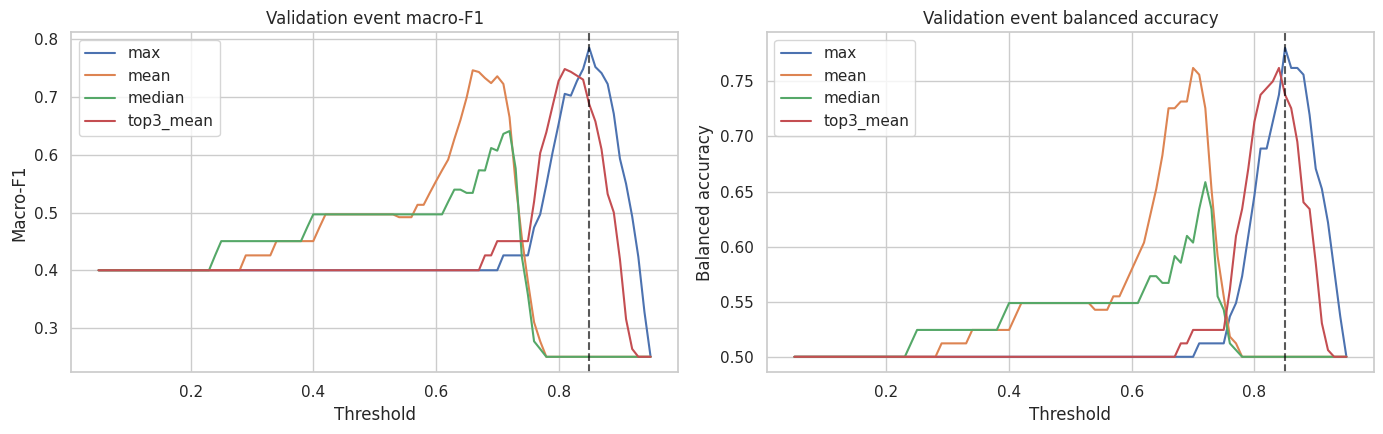

In [47]:
best_probs = load_probabilities(best_run_dir)
assert all(len(best_probs[p]) == len(split_frames[p]) for p in ('train', 'val', 'test'))
rule_search, selected_rule = select_event_rule(split_frames['val'], best_probs['val'])
SELECTED_AGGREGATION = selected_rule['Source']
SELECTED_THRESHOLD = float(selected_rule['Threshold'])
aggregation_best = (rule_search.sort_values(['Macro-F1', 'Balanced accuracy'], ascending=False).groupby('Source', as_index=False).first().sort_values('Macro-F1', ascending=False))
display(Markdown(f'### Locked rule: **{SELECTED_AGGREGATION}**, threshold **{SELECTED_THRESHOLD:.2f}** — selected only on Validation (q4)'))
display(aggregation_best[['Source', 'Threshold', 'Accuracy', 'Balanced accuracy', 'Macro-F1', 'ROC-AUC', 'PR-AUC']].rename(columns={'Source': 'Aggregation'}).style.hide(axis='index').format({c: '{:.4f}' for c in ['Threshold', 'Accuracy', 'Balanced accuracy', 'Macro-F1', 'ROC-AUC', 'PR-AUC']}).background_gradient(subset=['Macro-F1'], cmap='Blues'))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for method, group in rule_search.groupby('Source'):
    axes[0].plot(group['Threshold'], group['Macro-F1'], label=method)
    axes[1].plot(group['Threshold'], group['Balanced accuracy'], label=method)
for ax, title, ylabel in zip(axes, ['Validation event macro-F1', 'Validation event balanced accuracy'], ['Macro-F1', 'Balanced accuracy']):
    ax.axvline(SELECTED_THRESHOLD, color='black', linestyle='--', alpha=.65)
    ax.set(title=title, xlabel='Threshold', ylabel=ylabel)
    ax.legend()
plt.tight_layout()
plt.show()

## 12. Frame, event, dan subject metrics — semua split
Semua tabel memakai nama split eksplisit. Frame-level memakai threshold 0.5 bawaan classifier. Event dan subject memakai aggregation serta threshold yang sudah dikunci dari Validation (q4).

In [54]:
level_data = {}
metric_rows = []
for part in ('train', 'val', 'test'):
    frame = split_frames[part][['event_id', 'subject_id', 'target']].copy()
    frame['probability'] = best_probs[part]
    event = aggregate_events(split_frames[part], best_probs[part], SELECTED_AGGREGATION)
    subject = aggregate_subjects(event)
    level_data[(part, 'Frame')] = frame
    level_data[(part, 'Event')] = event
    level_data[(part, 'Subject')] = subject
    metric_rows.append(metric_row(frame['target'].to_numpy(), frame['probability'].to_numpy(), 0.5, 'Frame', part, f'Best seed {best_seed}'))
    metric_rows.append(metric_row(event['target'].to_numpy(), event['probability'].to_numpy(), SELECTED_THRESHOLD, 'Event', part, f'Best seed {best_seed}'))
    metric_rows.append(metric_row(subject['target'].to_numpy(), subject['probability'].to_numpy(), SELECTED_THRESHOLD, 'Subject', part, f'Best seed {best_seed}'))
all_metrics = pd.DataFrame(metric_rows)
metric_columns = ['Level', 'Split', 'N', 'Threshold', 'Accuracy', 'Balanced accuracy', 'Macro-F1', 'Weighted-F1', 'Precision class 1', 'Recall class 1', 'ROC-AUC', 'PR-AUC']
display(all_metrics[metric_columns].style.hide(axis='index').format({c: '{:.4f}' for c in metric_columns if c not in {'Level', 'Split', 'N'}}).background_gradient(subset=['Macro-F1', 'Balanced accuracy'], cmap='Blues'))

for level in ('Frame', 'Event', 'Subject'):
    display(Markdown(f'### {level}-level classification reports'))
    display_reports_one_row(level, level_data)

Level,Split,N,Threshold,Accuracy,Balanced accuracy,Macro-F1,Weighted-F1,Precision class 1,Recall class 1,ROC-AUC,PR-AUC
Frame,Train (q1–q3),10195,0.5000,0.6980,0.5871,0.5671,0.6371,0.6910,0.9644,0.7052,0.7999
Event,Train (q1–q3),422,0.8500,0.8175,0.8136,0.8055,0.8195,0.8824,0.8272,0.8700,0.9178
Subject,Train (q1–q3),88,0.8500,0.7841,0.7826,0.7818,0.7843,0.8125,0.7959,0.8603,0.8711
Frame,Validation (q4),2960,0.5000,0.7024,0.5678,0.5416,0.6324,0.6998,0.9701,0.6077,0.7489
Event,Validation (q4),123,0.8500,0.8130,0.7805,0.7856,0.8111,0.8471,0.8780,0.8314,0.8994
Subject,Validation (q4),59,0.8500,0.8136,0.7923,0.7988,0.8108,0.8205,0.8889,0.8696,0.9170
Frame,Test (q5),2382,0.5000,0.7418,0.5427,0.5261,0.6802,0.7585,0.9558,0.6071,0.8130
Event,Test (q5),99,0.8500,0.7677,0.7187,0.7105,0.7716,0.8571,0.8219,0.8398,0.9350
Subject,Test (q5),49,0.8500,0.8163,0.8071,0.7877,0.8211,0.9062,0.8286,0.8714,0.9291


### Frame-level classification reports

,precision,recall,f1-score,support
0,0.7626,0.2098,0.3290,"3,599"
1,0.6910,0.9644,0.8051,"6,596"
accuracy,0.6980,0.6980,0.6980,"10,195"
macro avg,0.7268,0.5871,0.5671,"10,195"
weighted avg,0.7163,0.6980,0.6371,"10,195"
cross-entropy,0.5823,—,—,—
roc-auc,0.7052,—,—,—
score,0.6980,—,—,—
,precision,recall,f1-score,support
0,0.7342,0.1655,0.2701,985


### Event-level classification reports

,precision,recall,f1-score,support
0,0.7186,0.8000,0.7571,150
1,0.8824,0.8272,0.8539,272
accuracy,0.8175,0.8175,0.8175,422
macro avg,0.8005,0.8136,0.8055,422
weighted avg,0.8241,0.8175,0.8195,422
cross-entropy,0.6809,—,—,—
roc-auc,0.8700,—,—,—
score,0.8175,—,—,—
,precision,recall,f1-score,support
0,0.7368,0.6829,0.7089,41


### Subject-level classification reports

,precision,recall,f1-score,support
0,0.7500,0.7692,0.7595,39
1,0.8125,0.7959,0.8041,49
accuracy,0.7841,0.7841,0.7841,88
macro avg,0.7812,0.7826,0.7818,88
weighted avg,0.7848,0.7841,0.7843,88
cross-entropy,0.8344,—,—,—
roc-auc,0.8603,—,—,—
score,0.7841,—,—,—
,precision,recall,f1-score,support
0,0.8000,0.6957,0.7442,23


## 13. Confusion matrices, ROC, dan Precision–Recall
Setiap baris visual menampilkan Train (q1–q3), Validation (q4), dan Test (q5) berdampingan.

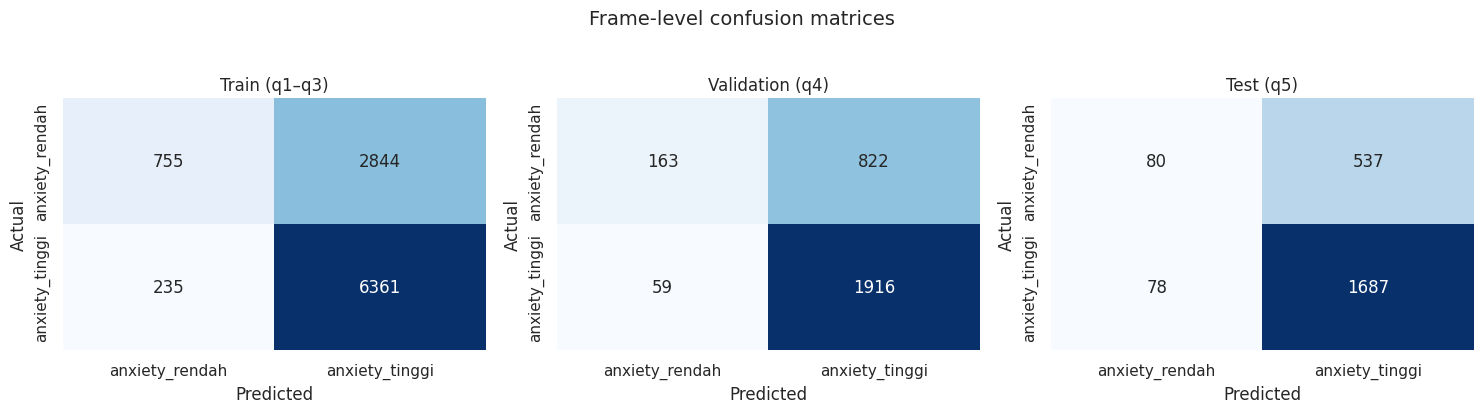

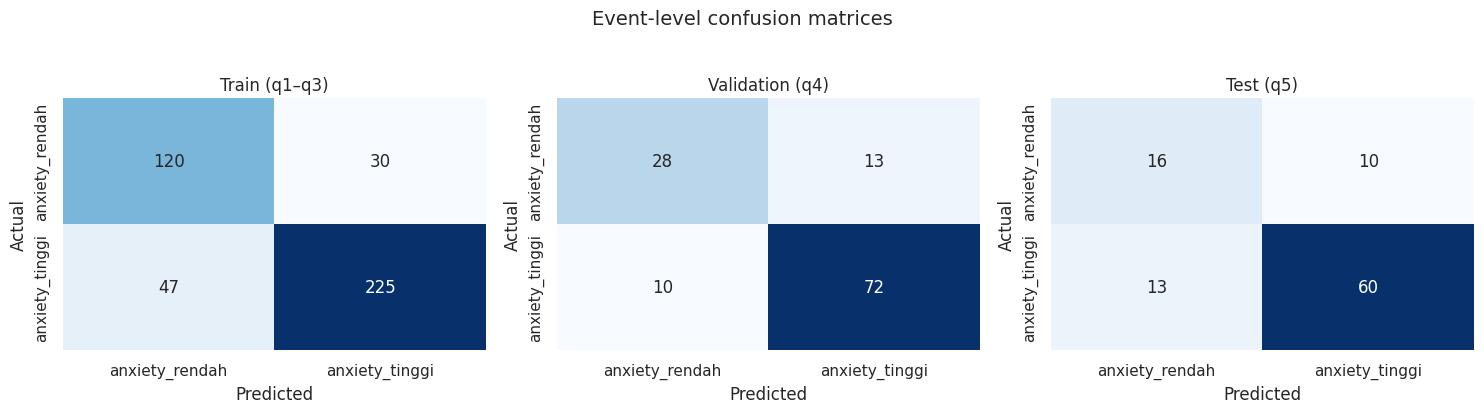

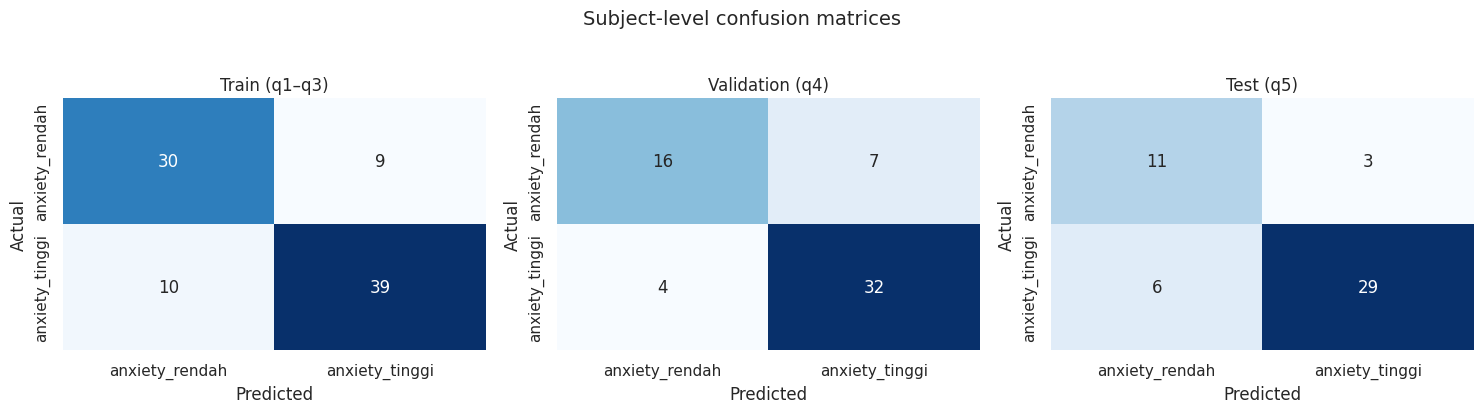

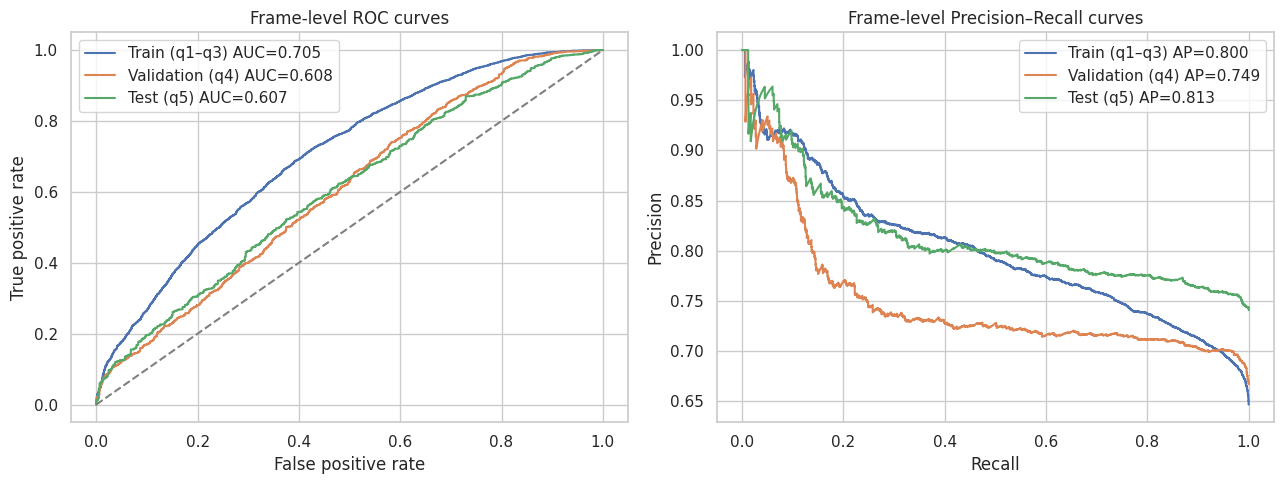

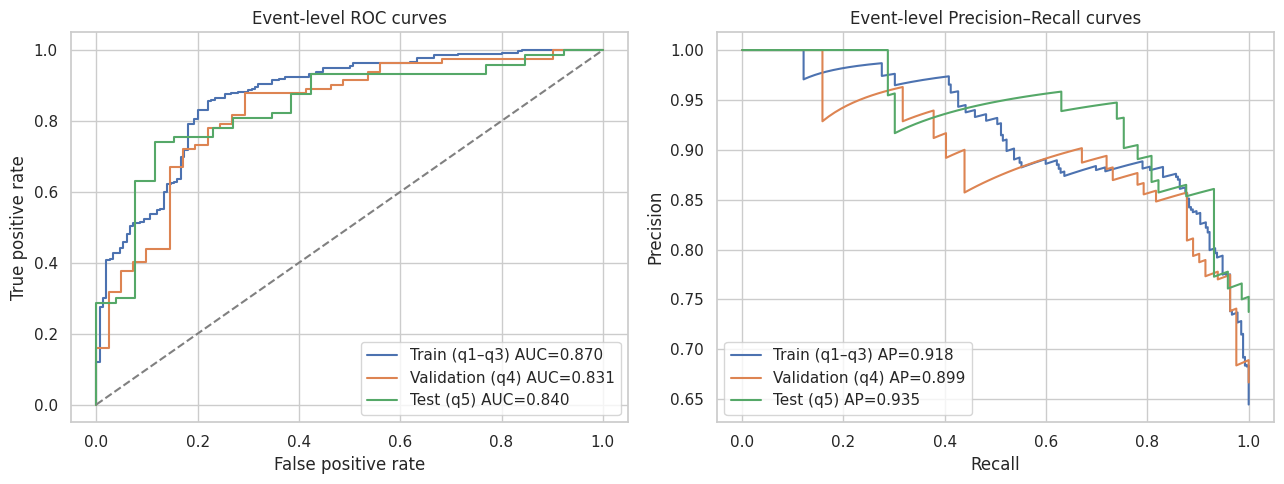

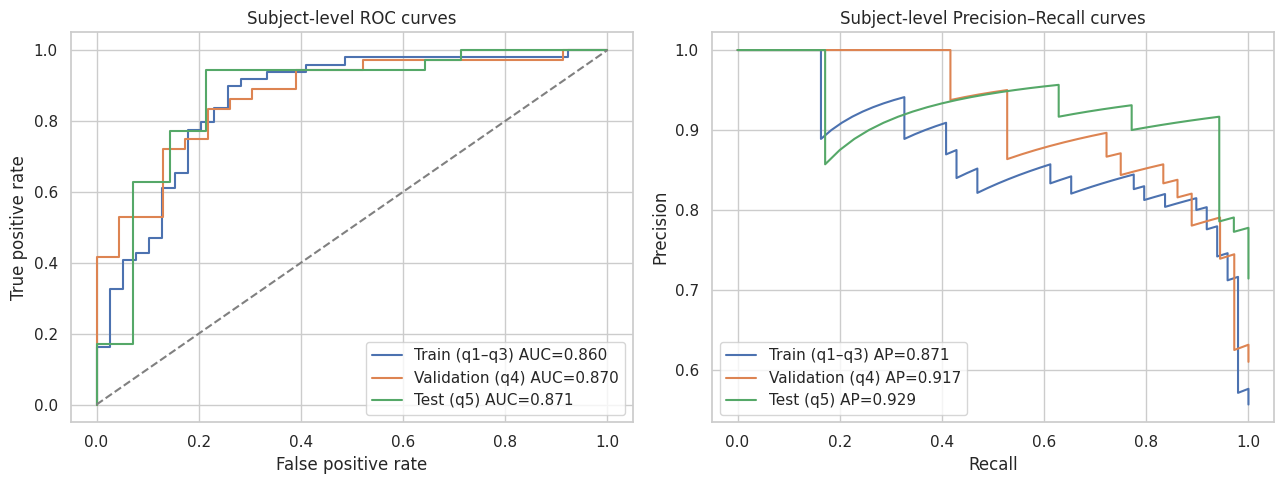

In [49]:
for level in ('Frame', 'Event', 'Subject'):
    threshold = 0.5 if level == 'Frame' else SELECTED_THRESHOLD
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, part in zip(axes, ('train', 'val', 'test')):
        data = level_data[(part, level)]
        pred = (data['probability'].to_numpy() >= threshold).astype(int)
        cm = confusion_matrix(data['target'], pred, labels=[0, 1])
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax, xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES)
        ax.set(title=SPLIT_LABELS[part], xlabel='Predicted', ylabel='Actual')
    fig.suptitle(f'{level}-level confusion matrices', fontsize=14, y=1.03)
    plt.tight_layout()
    plt.show()

for level in ('Frame', 'Event', 'Subject'):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    for part in ('train', 'val', 'test'):
        data = level_data[(part, level)]
        y = data['target'].to_numpy()
        p = data['probability'].to_numpy()
        fpr, tpr, _ = roc_curve(y, p)
        precision, recall, _ = precision_recall_curve(y, p)
        axes[0].plot(fpr, tpr, label=f"{SPLIT_LABELS[part]} AUC={roc_auc_score(y, p):.3f}")
        axes[1].plot(recall, precision, label=f"{SPLIT_LABELS[part]} AP={average_precision_score(y, p):.3f}")
    axes[0].plot([0, 1], [0, 1], '--', color='gray')
    axes[0].set(title=f'{level}-level ROC curves', xlabel='False positive rate', ylabel='True positive rate')
    axes[1].set(title=f'{level}-level Precision–Recall curves', xlabel='Recall', ylabel='Precision')
    axes[0].legend(); axes[1].legend()
    plt.tight_layout()
    plt.show()

## 14. Ensemble comparison
Tiga ensemble dibandingkan menggunakan rule yang dipilih pada Validation (q4) masing-masing. Best ensemble dipilih dari Validation (q4); hasil Test (q5) tetap hanya evaluasi terkunci.

### Best ensemble selected by Validation (q4): **Ensemble 1**

Ensemble,Split,Aggregation,Threshold,Accuracy,Balanced accuracy,Macro-F1,ROC-AUC,PR-AUC
0,Validation (q4),mean,0.6700,0.7805,0.7500,0.7515,0.8168,0.8752
0,Test (q5),mean,0.6700,0.7980,0.7516,0.7454,0.8772,0.9458
1,Validation (q4),mean,0.6700,0.7967,0.7378,0.7525,0.7951,0.8517
1,Test (q5),mean,0.6700,0.8081,0.6965,0.7178,0.8635,0.9396
2,Validation (q4),mean,0.6700,0.7724,0.7195,0.7294,0.7998,0.8644
2,Test (q5),mean,0.6700,0.8182,0.7529,0.7592,0.8672,0.9429


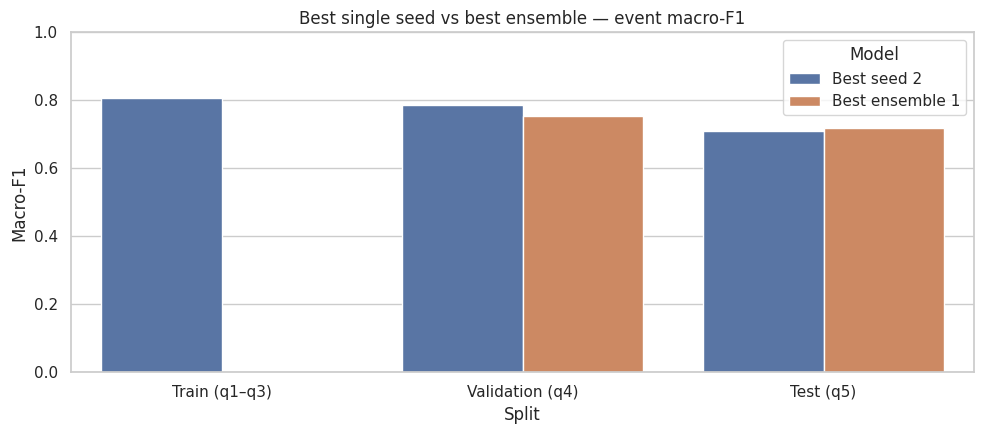

In [50]:
ensemble_rows = []
ensemble_rules = {}
if ENSEMBLE_DIR.exists():
    for ensemble_id in range(N_ENSEMBLES):
        run_dir = ENSEMBLE_DIR / str(ensemble_id)
        if not (run_dir / 'DONE').exists():
            continue
        probs = load_probabilities(run_dir)
        _, rule = select_event_rule(split_frames['val'], probs['val'])
        ensemble_rules[ensemble_id] = rule
        for part in ('val', 'test'):
            events = aggregate_events(split_frames[part], probs[part], rule['Source'])
            row = metric_row(events['target'].to_numpy(), events['probability'].to_numpy(), rule['Threshold'], 'Event', part, f'Ensemble {ensemble_id}')
            row['Ensemble'] = ensemble_id
            row['Aggregation'] = rule['Source']
            ensemble_rows.append(row)
ensemble_metrics = pd.DataFrame(ensemble_rows)
if ensemble_metrics.empty:
    display(Markdown('> Ensemble belum tersedia. Selesaikan training cell terlebih dahulu.'))
else:
    best_ensemble = int(ensemble_metrics[ensemble_metrics['Split'] == SPLIT_LABELS['val']].sort_values(['Macro-F1', 'Balanced accuracy'], ascending=False).iloc[0]['Ensemble'])
    display(Markdown(f'### Best ensemble selected by Validation (q4): **Ensemble {best_ensemble}**'))
    display(ensemble_metrics[['Ensemble', 'Split', 'Aggregation', 'Threshold', 'Accuracy', 'Balanced accuracy', 'Macro-F1', 'ROC-AUC', 'PR-AUC']].style.hide(axis='index').format({c: '{:.4f}' for c in ['Threshold', 'Accuracy', 'Balanced accuracy', 'Macro-F1', 'ROC-AUC', 'PR-AUC']}))
    comparison = pd.concat([
        seed_metrics[seed_metrics['Seed'] == best_seed].assign(Model=f'Best seed {best_seed}'),
        ensemble_metrics[ensemble_metrics['Ensemble'] == best_ensemble].assign(Model=f'Best ensemble {best_ensemble}'),
    ], ignore_index=True)
    plt.figure(figsize=(10, 4.5))
    sns.barplot(data=comparison, x='Split', y='Macro-F1', hue='Model')
    plt.title('Best single seed vs best ensemble — event macro-F1')
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()

## 15. Error analysis dan final artifacts
False positive dan false negative event ditampilkan untuk Validation (q4) dan Test (q5), lengkap dengan subject, confidence, panjang event, serta onset/apex/offset. Semua tabel utama disimpan agar laporan dapat dibuka tanpa menjalankan ulang training.

In [51]:
error_tables = {}
for part in ('val', 'test'):
    errors = level_data[(part, 'Event')].copy()
    errors['prediction'] = (errors['probability'] >= SELECTED_THRESHOLD).astype(int)
    errors['error_type'] = np.select(
        [(errors['target'] == 0) & (errors['prediction'] == 1), (errors['target'] == 1) & (errors['prediction'] == 0)],
        ['False positive', 'False negative'], default='Correct',
    )
    errors['confidence'] = np.where(errors['prediction'] == 1, errors['probability'], 1 - errors['probability'])
    errors = errors[errors['error_type'] != 'Correct'].sort_values('confidence', ascending=False)
    error_tables[part] = errors
    display(Markdown(f"### {SPLIT_LABELS[part]} event errors — {len(errors)} / {len(level_data[(part, 'Event')])}"))
    display(errors[['event_id', 'subject_id', 'target', 'prediction', 'error_type', 'probability', 'confidence', 'event_length', 'onset_frame', 'apex_frame', 'offset_frame']].style.hide(axis='index').format({'probability': '{:.4f}', 'confidence': '{:.4f}'}))

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
split_summary.to_csv(ARTIFACT_DIR / 'split_summary.csv', index=False)
trial_df.to_csv(ARTIFACT_DIR / 'tuning_trials.csv', index=False)
seed_metrics.to_csv(ARTIFACT_DIR / 'seed_stability.csv', index=False)
stability.to_csv(ARTIFACT_DIR / 'seed_mean_std.csv', index=False)
all_metrics.to_csv(ARTIFACT_DIR / 'best_seed_all_level_metrics.csv', index=False)
aggregation_best.to_csv(ARTIFACT_DIR / 'validation_aggregation_comparison.csv', index=False)
for part, errors in error_tables.items():
    errors.to_csv(ARTIFACT_DIR / f'{part}_event_errors.csv', index=False)
if not ensemble_metrics.empty:
    ensemble_metrics.to_csv(ARTIFACT_DIR / 'ensemble_comparison.csv', index=False)
final_manifest = {
    'split': {'train': 'q1-q3', 'validation': 'q4', 'test': 'q5'},
    'best_seed_selected_on_validation': best_seed,
    'event_aggregation_selected_on_validation': SELECTED_AGGREGATION,
    'event_threshold_selected_on_validation': SELECTED_THRESHOLD,
    'feature_count': len(FEATURE_COLS), 'features': FEATURE_COLS,
}
(ARTIFACT_DIR / 'manifest.json').write_text(json.dumps(final_manifest, indent=2))
display(Markdown(f'## Analysis artifacts saved to `{ARTIFACT_DIR}`'))
display(all_metrics[metric_columns].style.hide(axis='index').format({c: '{:.4f}' for c in metric_columns if c not in {'Level', 'Split', 'N'}}).background_gradient(subset=['Macro-F1', 'Balanced accuracy'], cmap='Greens'))

### Validation (q4) event errors — 23 / 123

event_id,subject_id,target,prediction,error_type,probability,confidence,event_length,onset_frame,apex_frame,offset_frame
key_firdausi_alfarel_before_q4_event_1,key_firdausi_alfarel_before,0,1,False positive,0.9316,0.9316,25,69,82,94
haikal_muhammad_rafli_after_q4_event_0,haikal_muhammad_rafli_after,0,1,False positive,0.9128,0.9128,24,9,21,33
luqman_ananta_abdul_hakim_after_q4_event_0,luqman_ananta_abdul_hakim_after,0,1,False positive,0.9052,0.9052,20,141,150,161
luqman_ananta_abdul_hakim_after_q4_event_1,luqman_ananta_abdul_hakim_after,0,1,False positive,0.9038,0.9038,24,152,162,176
akhmad_aakhif_athallah_after_q4_event_0,akhmad_aakhif_athallah_after,0,1,False positive,0.8999,0.8999,29,50,63,79
muhammad_farrel_caesarian_before_q4_event_0,muhammad_farrel_caesarian_before,0,1,False positive,0.8986,0.8986,30,57,71,87
luqman_ananta_abdul_hakim_after_q4_event_2,luqman_ananta_abdul_hakim_after,0,1,False positive,0.8816,0.8816,22,181,192,203
fiera_ziadattun_nisa_after_q4_event_1,fiera_ziadattun_nisa_after,0,1,False positive,0.8743,0.8743,16,38,47,54
luqman_ananta_abdul_hakim_after_q4_event_3,luqman_ananta_abdul_hakim_after,0,1,False positive,0.8711,0.8711,26,213,228,239
fiera_ziadattun_nisa_after_q4_event_0,fiera_ziadattun_nisa_after,0,1,False positive,0.8640,0.8640,21,0,9,21


### Test (q5) event errors — 23 / 99

event_id,subject_id,target,prediction,error_type,probability,confidence,event_length,onset_frame,apex_frame,offset_frame
muhammad_farrel_caesarian_after_q5_event_0,muhammad_farrel_caesarian_after,0,1,False positive,0.9183,0.9183,24,3,12,27
luqman_ananta_abdul_hakim_after_q5_event_0,luqman_ananta_abdul_hakim_after,0,1,False positive,0.9156,0.9156,23,2,11,25
fiera_ziadattun_nisa_after_q5_event_0,fiera_ziadattun_nisa_after,0,1,False positive,0.8823,0.8823,22,21,30,43
rizkya_salsabila_after_q5_event_1,rizkya_salsabila_after,0,1,False positive,0.8705,0.8705,26,74,84,100
fiera_ziadattun_nisa_before_q5_event_0,fiera_ziadattun_nisa_before,0,1,False positive,0.8684,0.8684,23,6,16,29
rizkya_salsabila_before_q5_event_3,rizkya_salsabila_before,0,1,False positive,0.8669,0.8669,22,216,225,238
fiera_ziadattun_nisa_before_q5_event_1,fiera_ziadattun_nisa_before,0,1,False positive,0.8608,0.8608,26,20,30,46
fiera_ziadattun_nisa_before_q5_event_2,fiera_ziadattun_nisa_before,0,1,False positive,0.8566,0.8566,23,46,55,69
luqman_ananta_abdul_hakim_after_q5_event_1,luqman_ananta_abdul_hakim_after,0,1,False positive,0.8533,0.8533,27,44,59,71
rizkya_salsabila_before_q5_event_2,rizkya_salsabila_before,0,1,False positive,0.8527,0.8527,21,168,177,189


## Analysis artifacts saved to `/home/ryuko/skripsi/Skripsi/Convat-1st/opticalflow/results/convat_opticalflow_behavioral_q123_q4_q5`

Level,Split,N,Threshold,Accuracy,Balanced accuracy,Macro-F1,Weighted-F1,Precision class 1,Recall class 1,ROC-AUC,PR-AUC
Frame,Train (q1–q3),10195,0.5000,0.6980,0.5871,0.5671,0.6371,0.6910,0.9644,0.7052,0.7999
Event,Train (q1–q3),422,0.8500,0.8175,0.8136,0.8055,0.8195,0.8824,0.8272,0.8700,0.9178
Subject,Train (q1–q3),88,0.8500,0.7841,0.7826,0.7818,0.7843,0.8125,0.7959,0.8603,0.8711
Frame,Validation (q4),2960,0.5000,0.7024,0.5678,0.5416,0.6324,0.6998,0.9701,0.6077,0.7489
Event,Validation (q4),123,0.8500,0.8130,0.7805,0.7856,0.8111,0.8471,0.8780,0.8314,0.8994
Subject,Validation (q4),59,0.8500,0.8136,0.7923,0.7988,0.8108,0.8205,0.8889,0.8696,0.9170
Frame,Test (q5),2382,0.5000,0.7418,0.5427,0.5261,0.6802,0.7585,0.9558,0.6071,0.8130
Event,Test (q5),99,0.8500,0.7677,0.7187,0.7105,0.7716,0.8571,0.8219,0.8398,0.9350
Subject,Test (q5),49,0.8500,0.8163,0.8071,0.7877,0.8211,0.9062,0.8286,0.8714,0.9291


## Interpretation checklist
- Gunakan **Event-level Test (q5) macro-F1, balanced accuracy, dan confusion matrix** sebagai hasil utama.
- Laporkan frame-level dan subject-level sebagai analisis pendukung.
- Laporkan **mean ± standard deviation 15 seed**, bukan hanya best seed.
- Nyatakan bahwa aggregation, threshold, best seed, dan best ensemble dipilih hanya pada Validation (q4).
- Jangan menyebut eksperimen ini subject-independent karena terdapat subject overlap antar-question.
- Train (q1–q3), Validation (q4), dan Test (q5) selalu ditampilkan eksplisit pada tabel dan grafik.